# 07 — Forecast evaluation, Diebold-Mariano, extensions (rolling correlation, DCC-GARCH)

**Project:** *Did Bitcoin miners leave Bitcoin for AI?* — Phase 7. The extensions (section 5) are in **Python**, with a DCC check in R in `notebooks/r/07_dcc.Rmd` (`rmgarch`).

| | |
|---|---|
| **Input** | **only** the `results/forecasts_*.csv` files from Phases 3 to 6, plus the panel for the extensions |
| **Outputs** | `results/model_comparison.csv`, `results/07_*.csv`, `figures/fig_07_*.png` |
| **Brief** | §6 (single MSE / RMSE / MAE / MAPE table, Diebold-Mariano, best model for the use case), §7 (dynamic correlation: rolling and DCC-GARCH) |

All models were evaluated with the **same protocol**:
* parameters estimated on the training sample only;
* rolling origins over the 123 test days (the last training day, then each test day);
* forecast of the CONVERTS index level at h = 5 and h = 10 days.

This gives **119 forecasts at h = 5 and 114 at h = 10 per model**, on exactly the same dates.

In [1]:
# Resolve the project root from wherever Jupyter was launched, so only relative paths are needed.
import sys, time, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config, data, arima, multivariate as mv, garch, dcc, metrics, plotting

SEED = config.set_seed()
cfg = config.load_config()
plotting.set_style()
pd.set_option("display.width", 190, "display.max_columns", 30, "display.precision", 4)
RES = config.path("results")
warnings.filterwarnings("ignore", category=FutureWarning)
print("root:", ROOT.name, "| seed:", SEED)

root: Bitcoin miners | seed: 42


In [2]:
# Read every price-forecast file of phases 3-6 (CONVERTS only) and check they share exactly the same targets.
files = ["forecasts_arima.csv", "forecasts_var.csv", "forecasts_vecm.csv", "forecasts_dl.csv"]
fc = pd.concat([pd.read_csv(RES / f, parse_dates=["date", "origin"]) for f in files], ignore_index=True)
fc = fc[fc["series"] == "CONVERTS"]
keys = fc.groupby("model")[["origin", "horizon"]].apply(lambda g: frozenset(map(tuple, g.to_numpy())))
assert keys.nunique() == 1, "models are not evaluated on the same (origin, horizon) pairs"
MODELS = list(fc["model"].unique())
print("models:", MODELS, "| rows per model:", fc.groupby("model").size().unique())

models: ['rw', 'arima_011', 'var1', 'var1_post', 'vecm_nvda', 'lstm', 'gru', 'hybrid_arima_lstm'] | rows per model: [1185]


## 1. Single summary table (h = 5 and h = 10)

**Error measures:** MSE, RMSE and MAE are in index points, MAPE in %.

> **Why MAPE is computed on the index level, not on returns.** MAPE divides the error by the observed value. A daily return is very often close to 0 (and changes sign), which would make MAPE explode and become meaningless. The index level always stays far from 0 (between ≈ 115 and 345 over the test set), so MAPE there is an interpretable relative error.

**Interpretability** (qualitative judgement, justified in the table) and **training time**:
* for the classical models, time is measured by re-estimating each model once on the training sample. This is the only exception to the rule "this notebook only reads the forecasts";
* for the networks, it is the training time of the chosen configuration, read from `06_grid.csv`. The full grid search (12 networks) and the walk-forward validation cost much more.

In [3]:
# Training time: refit each classical model once on the train sample (CPU, single run); DL times read from Phase 6.
panel = data.load_panel()
train, test = data.chrono_split(panel)
te = train.index[-1]
ret_tr = pd.DataFrame({s: panel[f"{s}_log_return"] for s in ["BTC", "NVDA", "CONVERTS", "PURE"]}).dropna().loc[:te]
lp_tr = panel[["CONVERTS_log_price", "NVDA_log_price"]].loc[:te].set_axis(["CONVERTS", "NVDA"], axis=1)
def timed(f, reps=3):
    t0 = time.perf_counter()
    for _ in range(reps):
        f()
    return (time.perf_counter() - t0) / reps
t_arima = timed(lambda: arima.fit_arima(panel["CONVERTS_log_price"].loc[:te], (0, 1, 1)))
grid = pd.read_csv(RES / "06_grid.csv")
g = lambda cell, inp: float(grid[(grid["cell"] == cell) & (grid["window"] == 10) & (grid["inputs"] == inp)]["seconds"].iloc[0])
TIME = {"rw": 0.0, "arima_011": t_arima,
        "var1": timed(lambda: mv.fit_var(ret_tr, 1)),
        "var1_post": timed(lambda: mv.fit_var(ret_tr.loc[cfg["pivot_date"]:], 1)),
        "vecm_nvda": timed(lambda: mv.fit_vecm(lp_tr, 1, 1)),
        "lstm": g("LSTM", "exogenous"), "gru": g("GRU", "exogenous"),
        "hybrid_arima_lstm": t_arima + g("LSTM", "univariate")}   # ARIMA + a univariate LSTM with the same architecture
INTERP = {"rw": ("high", "no parameter: tomorrow = today"),
          "arima_011": ("high", "1 readable MA coefficient"),
          "var1": ("medium", "16 coefficients + Granger / impulse responses"),
          "var1_post": ("medium", "same, on the recent regime"),
          "vecm_nvda": ("high", "equilibrium CONVERTS ≈ 0.98·NVDA, speed of return α, half-life"),
          "lstm": ("low", "≈ 5,000 weights, black box"), "gru": ("low", "≈ 4,000 weights, black box"),
          "hybrid_arima_lstm": ("low", "readable ARIMA part, opaque LSTM part")}
FAMILY = {"rw": "benchmark", "arima_011": "classical", "var1": "classical", "var1_post": "classical",
          "vecm_nvda": "classical", "lstm": "deep", "gru": "deep", "hybrid_arima_lstm": "deep (hybrid)"}
print({k: round(v, 4) for k, v in TIME.items()})

{'rw': 0.0, 'arima_011': 0.0593, 'var1': 0.0033, 'var1_post': 0.0022, 'vecm_nvda': 0.0018, 'lstm': 1.3, 'gru': 2.0, 'hybrid_arima_lstm': 1.6593}


In [4]:
# One table, all models, h = 5 and h = 10.
rows = []
for m in MODELS:
    for h in (5, 10):
        k = fc[(fc["model"] == m) & (fc["horizon"] == h)]
        cover = float(((k["y_true"] >= k["lower"]) & (k["y_true"] <= k["upper"])).mean() * 100)
        rows.append({"model": m, "family": FAMILY[m], "h": h, "n": len(k), **metrics.point_metrics(k["y_true"], k["y_pred"]),
                     "95% PI coverage": cover, "interpretability": INTERP[m][0], "why": INTERP[m][1],
                     "training time (s)": TIME[m]})
comp = pd.DataFrame(rows)
rw_rmse = comp[comp["model"] == "rw"].set_index("h")["RMSE"]
comp["RMSE / RMSE rw"] = comp.apply(lambda r: r["RMSE"] / rw_rmse[r["h"]], axis=1)
comp = comp.sort_values(["h", "RMSE"]).reset_index(drop=True)
comp.to_csv(RES / "model_comparison.csv", index=False)
comp.drop(columns="why").round(3)

,model,family,h,n,MSE,RMSE,MAE,MAPE_%,95% PI coverage,interpretability,training time (s),RMSE / RMSE rw
0,vecm_nvda,classical,5,119,776.321,27.863,22.378,9.935,97.479,high,0.002,0.969
1,rw,benchmark,5,119,827.588,28.768,23.470,10.471,96.639,high,0.000,1.000
2,arima_011,classical,5,119,832.196,28.848,23.548,10.499,98.319,high,0.059,1.003
3,hybrid_arima_lstm,deep (hybrid),5,119,846.337,29.092,23.810,10.620,96.639,low,1.659,1.011
4,var1,classical,5,119,849.829,29.152,23.892,10.685,99.160,medium,0.003,1.013
5,lstm,deep,5,119,871.984,29.529,24.201,10.900,96.639,low,1.300,1.026
6,gru,deep,5,119,908.037,30.134,24.780,11.229,96.639,low,2.000,1.047
7,var1_post,classical,5,119,924.722,30.409,25.286,11.467,96.639,medium,0.002,1.057
8,vecm_nvda,classical,10,114,1140.829,33.776,27.001,12.781,98.246,high,0.002,0.936
9,rw,benchmark,10,114,1303.033,36.098,28.267,13.613,98.246,high,0.000,1.000


figures\fig_07_01_model_comparison.png


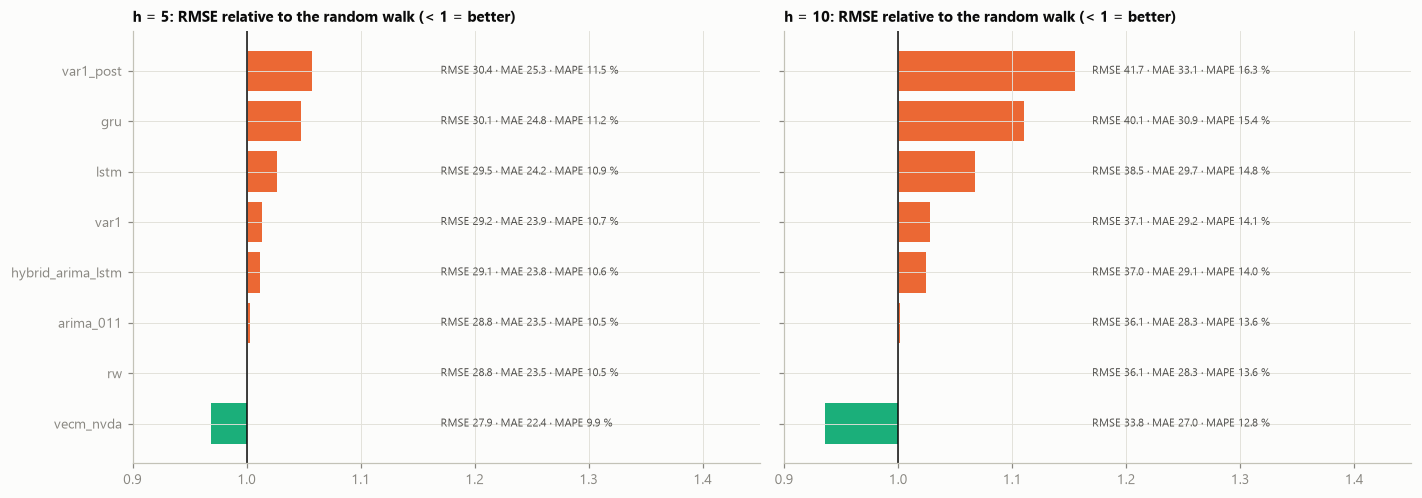

In [5]:
# Formatted figure of the table: RMSE ratio to the random walk per model and horizon, with the raw metrics printed.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
order = comp[comp["h"] == 5].sort_values("RMSE")["model"].tolist()
for ax, h in zip(axes, (5, 10)):
    k = comp[comp["h"] == h].set_index("model").loc[order]
    cols = [plotting.SERIES[2] if v < 1 else (plotting.MUTED if m == "rw" else plotting.SERIES[1]) for m, v in k["RMSE / RMSE rw"].items()]
    ax.barh(range(len(k)), k["RMSE / RMSE rw"] - 1, left=1, color=cols)
    ax.axvline(1, color=plotting.INK, lw=1)
    for i, (m, r) in enumerate(k.iterrows()):
        ax.text(1.17, i, f"RMSE {r['RMSE']:.1f} · MAE {r['MAE']:.1f} · MAPE {r['MAPE_%']:.1f} %",
                va="center", fontsize=7.5, color=plotting.INK2)
    ax.set_yticks(range(len(k))); ax.set_yticklabels(k.index); ax.invert_yaxis()
    ax.set_xlim(0.9, 1.45); ax.set_title(f"h = {h}: RMSE relative to the random walk (< 1 = better)")
fig.tight_layout(); print(plotting.save(fig, "fig_07_01_model_comparison")); plt.show()

**Reading the table** (`results/model_comparison.csv`, fig. 07_01):

| Rank | Model | RMSE h=5 (ratio to rw) | RMSE h=10 (ratio to rw) | MAPE h=5 / h=10 | Interpretability | Time (order of magnitude) |
|---|---|---|---|---|---|---|
| 1 | **vecm_nvda** | **27.86 (0.969)** | **33.78 (0.936)** | **9.9% / 12.8%** | high | a few ms |
| 2 | rw | 28.77 (1) | 36.10 (1) | 10.5% / 13.6% | high | none |
| 3 | arima_011 | 28.85 (1.003) | 36.15 (1.001) | 10.5% / 13.6% | high | < 0.5 s |
| 4 | hybrid_arima_lstm | 29.09 (1.011) | 36.99 (1.025) | 10.6% / 14.0% | low | ≈ 1 to 2 s |
| 5 | var1 | 29.15 (1.013) | 37.10 (1.028) | 10.7% / 14.1% | medium | a few ms |
| 6 | lstm | 29.53 (1.026) | 38.53 (1.068) | 10.9% / 14.8% | low | ≈ 1 to 2 s |
| 7 | gru | 30.13 (1.047) | 40.07 (1.110) | 11.2% / 15.4% | low | ≈ 1 to 2 s |
| 8 | var1_post | 30.41 (1.057) | 41.71 (1.155) | 11.5% / 16.3% | medium | a few ms |

* **Same ranking for every measure and both horizons.** RMSE, MAE and MAPE rank the models in the same order at h = 5 and h = 10: the ranking does not depend on the chosen metric.
* **Only one model does better than the random walk**: the CONVERTS–NVDA VECM (−3.1% RMSE at h = 5, −6.4% at h = 10). All others do as well or worse, and the gap grows with the horizon.
* **The 95% intervals** cover the realised value in 96 to 99% of cases for the classical models, but only 90% at h = 10 for the LSTM and GRU: their empirical intervals are too narrow.
* **Computing cost** (measured times vary from run to run; only orders of magnitude matter). Classical models are estimated in under half a second, VAR and VECM in a few milliseconds. A final network takes 1 to 2 s, but selecting it required 12 trainings (34.5 s in total) plus 10 walk-forward trainings, on a single core.

## 2. Are the differences significant? Diebold-Mariano test

The test is implemented in `src/metrics.py` (`dm_test`, with a docstring). Its unit test, `tests/test_metrics.py`, reproduces the values of R's `forecast::dm.test` to within 10⁻⁸.

* **H0: the two models have the same accuracy**, i.e. the mean of the loss differential d_t = L(e₁,t) − L(e₂,t) is zero. Loss: squared error (consistent with RMSE).
* **Statistic.** DM = mean(d) / √(V/n), where V is the long-run variance including the h − 1 autocovariances: h-day forecasts made every day overlap, so successive errors are correlated.
* **Harvey-Leybourne-Newbold (HLN) correction** for small samples: DM* = DM·√((n + 1 − 2h + h(h−1)/n)/n), compared with a Student-t distribution with n − 1 degrees of freedom.
* **Reading.** DM* > 0 means model 1 has the larger loss, so model 2 (here the random walk) is better. H0 is rejected if p < 0.05.

**Why not just use RMSE?** Two RMSEs computed on 119 noisy forecasts can differ by chance. The DM test says whether the gap is larger than what noise would produce under H0.

In [6]:
# Each model vs the random walk, then best classical vs best deep model (by RMSE at h = 5).
def dm_pair(m1, m2, h):
    a = fc[(fc["model"] == m1) & (fc["horizon"] == h)].sort_values("origin")
    b = fc[(fc["model"] == m2) & (fc["horizon"] == h)].sort_values("origin")
    assert (a["origin"].to_numpy() == b["origin"].to_numpy()).all()
    la, lb = (a["y_true"] - a["y_pred"]) ** 2, (b["y_true"] - b["y_pred"]) ** 2
    r = metrics.dm_test(la, lb, h=h)
    r["p NW(20)"] = metrics.dm_test(la, lb, h=h, nw_lags=20)["p_value"]      # robustness: longer-memory variance
    better = m1 if r["mean_d"] < 0 else m2
    concl = f"significant difference: {better} more accurate" if r["p_value"] < 0.05 else "no significant difference"
    return {"model 1": m1, "model 2": m2, "h": h, **r, "conclusion (5%)": concl}
dm_rows = [dm_pair(m, "rw", h) for m in MODELS if m != "rw" for h in (5, 10)]
r5 = comp[comp["h"] == 5].set_index("model")["RMSE"]
best_classic = r5[[m for m in MODELS if FAMILY[m] == "classical"]].idxmin()
best_deep = r5[[m for m in MODELS if FAMILY[m].startswith("deep")]].idxmin()
dm_rows += [dm_pair(best_classic, best_deep, h) for h in (5, 10)]
dm_tab = pd.DataFrame(dm_rows)
dm_tab.to_csv(RES / "07_dm_tests.csv", index=False)
print("best classical:", best_classic, "| best deep:", best_deep)
dm_tab[["model 1", "model 2", "h", "n", "mean_d", "DM", "p_value", "p NW(20)", "conclusion (5%)"]].round(4)

best classical: vecm_nvda | best deep: hybrid_arima_lstm


,model 1,model 2,h,n,mean_d,DM,p_value,p NW(20),conclusion (5%)
0,arima_011,rw,5,119,4.6084,1.3796,0.1703,0.2373,no significant difference
1,arima_011,rw,10,114,3.7193,0.6643,0.5078,0.4766,no significant difference
2,var1,rw,5,119,22.2409,1.4159,0.1594,0.1254,no significant difference
3,var1,rw,10,114,73.0649,1.5461,0.1249,0.0980,no significant difference
4,var1_post,rw,5,119,97.1342,1.6756,0.0965,0.0502,no significant difference
5,var1_post,rw,10,114,436.5159,1.8291,0.0700,0.0467,no significant difference
6,vecm_nvda,rw,5,119,-51.2673,-0.6889,0.4922,0.3924,no significant difference
7,vecm_nvda,rw,10,114,-162.2045,-0.6373,0.5252,0.4881,no significant difference
8,lstm,rw,5,119,44.3966,1.2091,0.2290,0.1979,no significant difference
9,lstm,rw,10,114,181.8705,1.0075,0.3158,0.2839,no significant difference


In [7]:
# Same test on the volatility forecasts of Phase 5 (QLIKE loss): GARCH(1,1)-t vs constant variance.
fv = pd.read_csv(RES / "forecasts_garch_vol.csv", parse_dates=["date", "origin"])
ql = lambda k: (k["y_true"].clip(lower=1e-6) / k["y_pred"] - np.log(k["y_true"].clip(lower=1e-6) / k["y_pred"]) - 1).to_numpy()
vrows = []
for s in ("CONVERTS", "PURE", "BTC"):
    for h in (5, 10):
        a = fv[(fv["series"] == s) & (fv["model"] == "garch_t") & (fv["horizon"] == h)].sort_values("origin")
        b = fv[(fv["series"] == s) & (fv["model"] == "const_var") & (fv["horizon"] == h)].sort_values("origin")
        r = metrics.dm_test(ql(a), ql(b), h=h)
        nw = metrics.dm_test(ql(a), ql(b), h=h, nw_lags=20)
        vrows.append({"series": s, "model 1": "garch_t", "model 2": "const_var", "h": h, **r, "DM NW(20)": nw["DM"], "p NW(20)": nw["p_value"],
                      "conclusion (5%)": ("garch_t more accurate" if r["mean_d"] < 0 else "const_var more accurate") if r["p_value"] < 0.05 else "no significant difference"})
dm_vol = pd.DataFrame(vrows)
dm_vol.to_csv(RES / "07_dm_vol.csv", index=False)
dm_vol[["series", "h", "mean_d", "DM", "p_value", "DM NW(20)", "p NW(20)", "conclusion (5%)"]].round(4)

,series,h,mean_d,DM,p_value,DM NW(20),p NW(20),conclusion (5%)
0,CONVERTS,5,0.0072,0.9013,0.3693,0.8019,0.4242,no significant difference
1,CONVERTS,10,0.0056,1.0014,0.3188,0.8308,0.4078,no significant difference
2,PURE,5,-0.0172,-0.6561,0.5130,-0.6259,0.5326,no significant difference
3,PURE,10,-0.0174,-0.7011,0.4847,-0.6409,0.5229,no significant difference
4,BTC,5,-0.0658,-1.5948,0.1134,-1.8241,0.0707,no significant difference
5,BTC,10,-0.0470,-10.5155,0.0000,-2.8948,0.0046,garch_t more accurate


**Level forecasts (loss = squared error).**
* **No model is significantly better than the random walk.**
  * The VECM, the best by RMSE, gives DM = −0.69 (p = 0.49) at h = 5 and −0.64 (p = 0.53) at h = 10. Its 3 to 6% RMSE gain **cannot be distinguished from chance** on 119 forecasts.
  * ARIMA(0,1,1), VAR(1), LSTM and GRU are not significantly different from the random walk either (p between 0.12 and 0.51).
* **One model is significantly worse: the hybrid** (DM = 2.66, p = 0.009 at h = 5; 2.71, p = 0.008 at h = 10). Its extra error is small but very **regular**: it is the constant upward drift of its LSTM component (Phase 6). A small but systematic difference is easier to detect than a larger but noisy one, like the LSTM alone (p = 0.23).
* **The VAR estimated on the recent regime only** (`var1_post`) is borderline: p = 0.097 and 0.070 with the standard variance, 0.050 and 0.047 with the Newey-West variance (20 lags). It is probably worse than the random walk.
* **Best classical vs best deep** (VECM vs hybrid): no significant difference (p = 0.38 and 0.40).
* **Caution about multiple testing.** We run 16 tests; with a Bonferroni correction (threshold 0.05 / 16 ≈ 0.003), even the rejection for the hybrid would no longer be significant. The substantive conclusions do not change: **nothing demonstrably beats the random walk.**

**Volatility forecasts (QLIKE loss, GARCH(1,1)-t vs constant variance).**
* **CONVERTS**: no difference (p = 0.37 and 0.32). This is consistent with the absence of an ARCH effect.
* **PURE**: GARCH has a lower QLIKE, but the difference is not significant (p = 0.51 and 0.48).
* **BTC**: GARCH is better. At h = 5, it is not significant (p = 0.11; Newey-West: 0.07). At h = 10, the standard statistic is −10.5, but both variance forecasts move very slowly: the loss differential stays autocorrelated well beyond h − 1 lags, and the standard variance is underestimated. With Newey-West (20 lags), DM = −2.89 (p = 0.005): **GARCH remains significantly better for BTC at h = 10**, with a more reasonable statistic.

## 3. Forecasts and intervals of the three best models (h = 5)

figures\fig_07_02_top3_forecasts.png


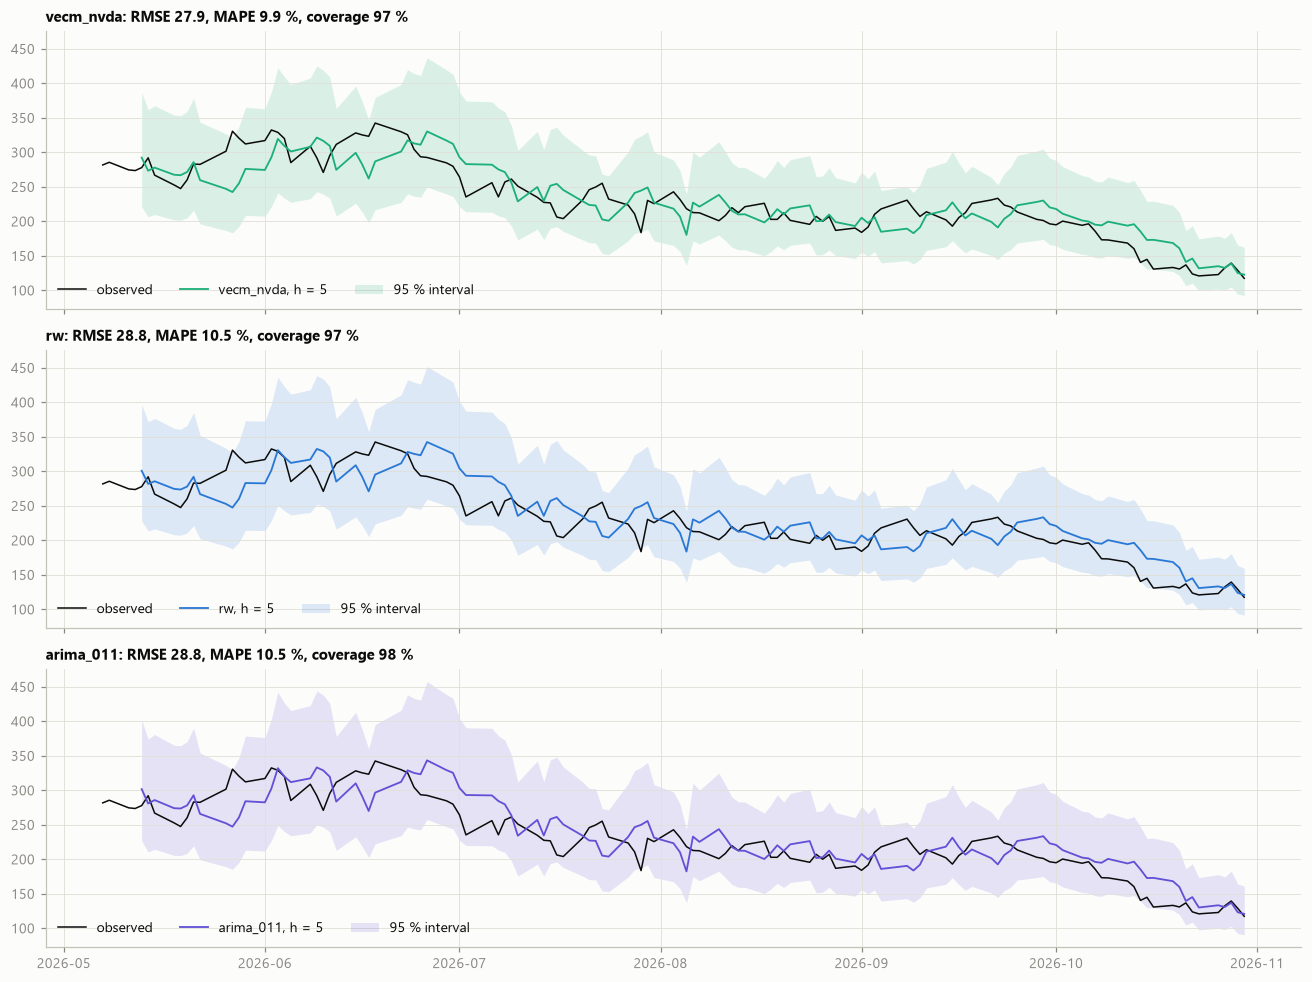

top 3: ['vecm_nvda', 'rw', 'arima_011']


In [8]:
# Three best models by RMSE at h = 5: 5-day-ahead forecast with its 95 % interval, against the observed index.
top3 = comp[comp["h"] == 5].sort_values("RMSE")["model"].head(3).tolist()
obs = fc[(fc["model"] == "rw") & (fc["horizon"] == 1)].set_index("date")["y_true"]
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, sharey=True)
for ax, m, col in zip(axes, top3, [plotting.SERIES[2], plotting.SERIES[0], plotting.SERIES[6]]):
    k = fc[(fc["model"] == m) & (fc["horizon"] == 5)].sort_values("date")
    ax.plot(obs.index, obs, color=plotting.INK, lw=1, label="observed")
    ax.plot(k["date"], k["y_pred"], color=col, lw=1.2, label=f"{m}, h = 5")
    ax.fill_between(k["date"], k["lower"], k["upper"], color=col, alpha=0.15, lw=0, label="95 % interval")
    r = comp[(comp["model"] == m) & (comp["h"] == 5)].iloc[0]
    ax.set_title(f"{m}: RMSE {r['RMSE']:.1f}, MAPE {r['MAPE_%']:.1f} %, coverage {r['95% PI coverage']:.0f} %"); ax.legend(loc="lower left", ncol=3)
fig.tight_layout(); print(plotting.save(fig, "fig_07_02_top3_forecasts")); plt.show()
print("top 3:", top3)

## 4. Conclusion: which model for which use?

**Use case: forecasting the level of the converted miners' index 1 to 2 weeks ahead** (for example to size a position or a risk budget).

1. **Accuracy.**
   * The CONVERTS–NVDA VECM has the smallest errors (RMSE −3% at h = 5, −6% at h = 10 relative to the random walk), with well-calibrated intervals (97 to 98%).
   * **The Diebold-Mariano test shows that this gain is not significant** (p ≈ 0.5).
   * No other model does better than the random walk, and the hybrid even does significantly worse.
2. **Interpretability.**
   * The random walk and the VECM are the easiest to read: the VECM says that CONVERTS follows NVDA in the long run (β ≈ 1) and corrects a gap in ≈ 2 to 3 months.
   * The networks are black boxes.
3. **Computing cost.** The random walk is free, the VECM almost free (a few milliseconds). The networks require a hyperparameter search, walk-forward validation and control of the random seed, for a worse result.
4. **Robustness.** The CONVERTS–NVDA cointegration is **borderline** (Phase 4: R does not keep it with its table of critical values) and was not detected after the pivot. The VECM's good result on this test set may therefore not repeat.

**Recommendation.**
* **Operational benchmark: the random walk.** No model beats it in a statistically demonstrated way, and it has neither cost nor overfitting risk. Its intervals (ARIMA(0,1,0) with Student-t, or GARCH for risk) remain useful.
* **Model to monitor: the CONVERTS–NVDA VECM.** It is the best trade-off between accuracy, interpretability and cost, and it expresses the new AI exposure in economic terms. To be used **alongside** the random walk and re-evaluated when more post-pivot data are available.
* **Deep learning: not recommended for this use.** It is less accurate, opaque, more expensive, and its intervals are poorly calibrated.
* **For volatility**: GARCH(1,1)-t for BTC (significantly better at h = 10) and for PURE (better but not significant); constant variance for CONVERTS.

## 5. Extensions (bonus, §7): dynamic correlation

### 5.1 90-day rolling correlation: the key figure of the project

On a single chart: correlation of the returns of CONVERTS and PURE with BTC and with NVDA, over a 90-trading-day window (≈ 4 months, more reactive than the 120 days of Phase 2), with the pivot date. The question is whether, for the converts, the "NVDA" line crosses the "BTC" line.

figures\fig_07_03_rolling_corr_crossing.png


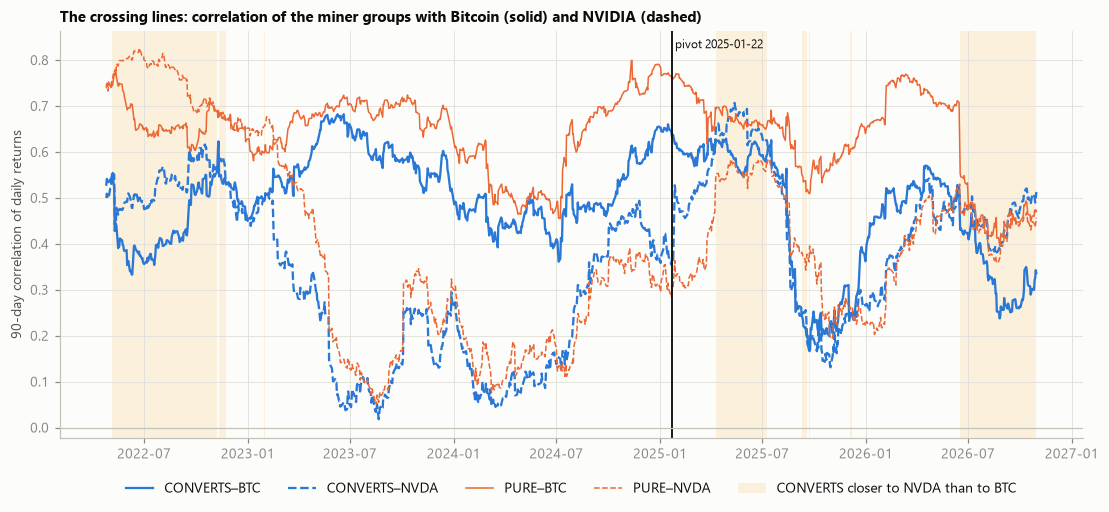

periods where CONVERTS-NVDA > CONVERTS-BTC: [('2022-05-05', '2022-11-08'), ('2022-11-11', '2022-11-25'), ('2023-01-30', '2023-02-01'), ('2023-02-03', '2023-02-06'), ('2025-04-07', '2025-04-08'), ('2025-04-10', '2025-07-11'), ('2025-08-26', '2025-08-28'), ('2025-08-29', '2025-09-02'), ('2025-09-09', '2025-09-19'), ('2025-09-22', '2025-09-25')]


,share of days CONVERTS–NVDA > CONVERTS–BTC,share of days PURE–NVDA > PURE–BTC
pre-pivot,0.205,0.260
post-pivot,0.396,0.034


In [9]:
# Rolling 90-day correlations of both groups with both references; record when CONVERTS-NVDA exceeds CONVERTS-BTC.
ret = pd.DataFrame({s: panel[f"{s}_log_return"] for s in ["CONVERTS", "PURE", "BTC", "NVDA"]}).dropna()
PIV = pd.Timestamp(cfg["pivot_date"])
rc = pd.DataFrame({f"{g}–{r}": ret[g].rolling(90).corr(ret[r]) for g in ("CONVERTS", "PURE") for r in ("BTC", "NVDA")}).dropna()
rc.to_csv(RES / "07_rolling_corr_90.csv")
fig, ax = plt.subplots(figsize=(12, 4.8))
style = {"CONVERTS–BTC": (plotting.CORE["CONVERTS"], "-"), "CONVERTS–NVDA": (plotting.CORE["CONVERTS"], "--"),
         "PURE–BTC": (plotting.CORE["PURE"], "-"), "PURE–NVDA": (plotting.CORE["PURE"], "--")}
for c, (col, ls) in style.items():
    ax.plot(rc.index, rc[c], color=col, ls=ls, lw=1.5 if c.startswith("CONVERTS") else 1.0, label=c)
cross = rc["CONVERTS–NVDA"] > rc["CONVERTS–BTC"]
ax.fill_between(rc.index, 0, 1, where=cross, transform=ax.get_xaxis_transform(), color=plotting.CORE["NVDA"], alpha=0.12, lw=0,
                label="CONVERTS closer to NVDA than to BTC")
ax.axvline(PIV, color=plotting.INK, lw=1.2); ax.text(PIV, 0.98, " pivot 2025-01-22", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
ax.axhline(0, color=plotting.AXIS, lw=0.8)
ax.set_ylabel("90-day correlation of daily returns"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5)
ax.set_title("The crossing lines: correlation of the miner groups with Bitcoin (solid) and NVIDIA (dashed)")
print(plotting.save(fig, "fig_07_03_rolling_corr_crossing")); plt.show()
share = pd.DataFrame({"share of days CONVERTS–NVDA > CONVERTS–BTC": [cross[rc.index < PIV].mean(), cross[rc.index >= PIV].mean()],
                      "share of days PURE–NVDA > PURE–BTC": [(rc["PURE–NVDA"] > rc["PURE–BTC"])[rc.index < PIV].mean(),
                                                                (rc["PURE–NVDA"] > rc["PURE–BTC"])[rc.index >= PIV].mean()]},
                     index=["pre-pivot", "post-pivot"])
runs = cross.astype(int).diff().fillna(0)
print("periods where CONVERTS-NVDA > CONVERTS-BTC:",
      [(str(a.date()), str(b.date())) for a, b in zip(rc.index[(runs == 1)], rc.index[(runs == -1)])][:10])
share.round(3)

**Reading the key figure (fig. 07_03).**
* **Before the pivot**, the correlation of CONVERTS with NVDA exceeds the one with BTC only 20.5% of the time, almost entirely in May – November 2022. That was a bear market in which all risky assets were correlated with NVDA, the pure miners too: PURE–NVDA > PURE–BTC 26% of the time before the pivot.
* **After the pivot**, the CONVERTS lines cross **39.6% of the time**, vs **3.4%** for PURE. Three episodes:
  * **April – July 2025** (62 days): CONVERTS–NVDA reaches 0.64 at the end of June 2025, above CONVERTS–BTC (0.59);
  * several brief crossings in **August – September 2025**, when CONVERTS–BTC collapses (from 0.64 the day before the pivot to **0.17 on 2025-09-23**, its minimum);
  * **from mid-June 2026 to the end of the sample** (95 days): on 2026-10-30, CONVERTS–NVDA is 0.51 vs 0.34 for CONVERTS–BTC.
* **The PURE control stays on the BTC side** almost all the time after the pivot (PURE–BTC 0.47 vs PURE–NVDA 0.46 on 2026-10-30, but 0.58 vs 0.26 in November 2025).
* **The lines do cross for the converts, and only for them.** But it is not a definitive switch: both correlations stay of the same order and swap places several times. The link with BTC weakens without disappearing. This confirms Phases 4 and 5: an AI exposure **that adds to** the link with Bitcoin.

### 5.2 DCC-GARCH (dynamic conditional correlation)

Two-step DCC(1,1) (Engle, 2002), implemented in `src/dcc.py`:
1. for each series, a GARCH(1,1)-t (the Phase 5 model) gives the standardised residuals z_t;
2. the correlation follows Q_t = (1 − a − b)·Q̄ + a·z_{t−1}z′_{t−1} + b·Q_{t−1}. Parameter **a** measures how the correlation reacts to a common shock, **b** its persistence.

Estimation on the full sample (descriptive use), for the pairs CONVERTS–BTC, CONVERTS–NVDA, then the two control pairs with PURE. The implementation is **checked against `rmgarch` in R** (`07_dcc.Rmd`).

In [10]:
# Step 1: GARCH(1,1)-t standardised residuals (percent returns, as in Phase 5); step 2: DCC on each pair.
r100 = 100 * ret
z = pd.DataFrame({s: garch.fit(r100[s], "GARCH(1,1)-t").std_resid for s in r100.columns}).dropna()
z.to_csv(RES / "07_dcc_std_resid.csv")
dres, drow = {}, []
for g in ("CONVERTS", "PURE"):
    for r in ("BTC", "NVDA"):
        d = dcc.fit_dcc(z[[g, r]])
        dres[f"{g}–{r}"] = d
        rho = d["rho"]
        drow.append({"pair": f"{g}–{r}", "a": d["a"], "b": d["b"], "a+b": d["a+b"], "loglik": d["loglik"], "converged": d["converged"],
                     "mean DCC corr pre-pivot": rho[rho.index < PIV].mean(), "mean DCC corr post-pivot": rho[rho.index >= PIV].mean(),
                     "min DCC corr": rho.min(), "max DCC corr": rho.max()})
dcc_tab = pd.DataFrame(drow)
dcc_tab.to_csv(RES / "07_dcc_params.csv", index=False)
pd.DataFrame({k: v["rho"] for k, v in dres.items()}).to_csv(RES / "07_dcc_corr.csv")
dcc_tab.round(4)

,pair,a,b,a+b,loglik,converged,mean DCC corr pre-pivot,mean DCC corr post-pivot,min DCC corr,max DCC corr
0,CONVERTS–BTC,0.0077,0.9721,0.9799,170.6474,True,0.5009,0.4768,0.3967,0.5547
1,CONVERTS–NVDA,0.0202,0.9703,0.9905,104.9061,True,0.3343,0.4184,0.0771,0.6404
2,PURE–BTC,0.0133,0.9501,0.9634,330.2377,True,0.6504,0.6341,0.5409,0.7629
3,PURE–NVDA,0.0328,0.9597,0.9924,153.0100,True,0.4091,0.4176,0.0095,0.7958


figures\fig_07_04_dcc_correlations.png


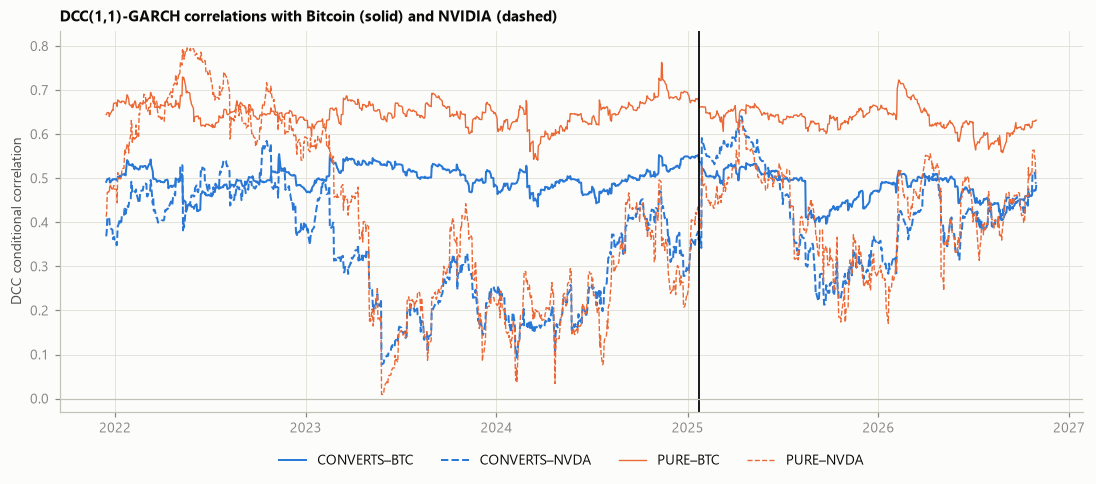

In [11]:
# DCC correlations over time, same colour code as the rolling-correlation chart.
fig, ax = plt.subplots(figsize=(12, 4.5))
for c, (col, ls) in style.items():
    ax.plot(dres[c]["rho"].index, dres[c]["rho"], color=col, ls=ls, lw=1.3 if c.startswith("CONVERTS") else 0.9, label=c)
ax.axvline(PIV, color=plotting.INK, lw=1.2); ax.axhline(0, color=plotting.AXIS, lw=0.8)
ax.set_ylabel("DCC conditional correlation"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
ax.set_title("DCC(1,1)-GARCH correlations with Bitcoin (solid) and NVIDIA (dashed)")
print(plotting.save(fig, "fig_07_04_dcc_correlations")); plt.show()

**DCC(1,1) results** (`07_dcc_params.csv`, fig. 07_04):

| Pair | a | b | a + b | Mean correlation before → after the pivot |
|---|---|---|---|---|
| CONVERTS–BTC | 0.008 | 0.972 | 0.980 | 0.501 → 0.477 |
| CONVERTS–NVDA | 0.020 | 0.970 | 0.991 | **0.334 → 0.418** |
| PURE–BTC | 0.013 | 0.950 | 0.963 | 0.650 → 0.634 |
| PURE–NVDA | 0.033 | 0.960 | 0.992 | 0.409 → 0.418 |

* **The model is stable.** The instructions planned for an unstable DCC; that is not the case here: the estimates converged, a + b < 1, and **`rmgarch` (R) finds the same parameters** (difference ≤ 0.002 on a and b). The R and Python correlation paths have a correlation ≥ 0.9996 (`07_dcc_r_vs_python.csv`). It can therefore be kept, alongside the rolling correlation.
* **The correlations are very persistent** (a + b between 0.96 and 0.99) and react slowly (small a). The DCC curves are smoother than the rolling correlations, but tell the same story.
* **Only the CONVERTS–NVDA pair changes clearly after the pivot** (+0.08 on average). CONVERTS–BTC falls slightly (−0.02), and the control pairs barely move (PURE–NVDA +0.01, PURE–BTC −0.02). As with the Phase 4 impulse responses, **the change specific to the converts is about NVDA**, not a break with BTC.
* **Limitation.** The pre-pivot means include 2022, when everything was correlated with NVDA. On 2023–2024 only, the before / after gap would be sharper (see fig. 07_04: CONVERTS–NVDA often between 0.1 and 0.3 from mid-2023 to mid-2024). This number is not computed here, hence the qualitative wording.

## Phase 7 summary

1. **Single table (8 models, h = 5 and 10)**: only the CONVERTS–NVDA VECM does better than the random walk (RMSE 27.9 vs 28.8 at h = 5, 33.8 vs 36.1 at h = 10). Then come ARIMA, hybrid, VAR, LSTM, GRU and post-pivot VAR. The ranking is the same for RMSE, MAE and MAPE (computed on the level, never on returns).
2. **Diebold-Mariano (HLN)**, implemented in `src/metrics.py`, tested against R to within 10⁻⁸: **no model is significantly better than the random walk** (VECM p = 0.49). The hybrid is significantly worse (p = 0.009), but this rejection does not survive a Bonferroni correction. In volatility, GARCH-t significantly beats constant variance only for BTC at h = 10 (p = 0.005 with Newey-West).
3. **Recommendation**: the random walk as the benchmark; the CONVERTS–NVDA VECM as the interpretable model to monitor (best, almost free, but non-significant gain and borderline cointegration); no deep learning for this use.
4. **The lines cross** (90-day rolling correlation): after the pivot, CONVERTS is more correlated with NVDA than with BTC 39.6% of the time, vs 3.4% for PURE. CONVERTS–BTC falls from 0.64 to 0.17 (September 2025), then rises back to 0.34.
5. **DCC-GARCH** (Python, checked with `rmgarch`): stable and persistent (a + b ≈ 0.96 to 0.99). Only the CONVERTS–NVDA correlation rises clearly after the pivot (0.334 → 0.418), with no break with BTC (0.501 → 0.477): **an AI exposure that adds to the link with Bitcoin, rather than an abandonment of Bitcoin.**